# Exploratory_Data_Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# import dataset
date_cols = ['order_purchase_timestamp', 'order_approved_at',
             'order_delivered_carrier_date', 'order_delivered_customer_date',
             'order_estimated_delivery_date']

order_items_date_columns = ['shipping_limit_date']

orders_cleaned      = pd.read_csv('../data/interim/olist_orders_cleaned.csv', parse_dates=date_cols)
order_items_cleaned = pd.read_csv('../data/interim/olist_order_items_cleaned.csv', parse_dates=order_items_date_columns)
customers_cleaned   = pd.read_csv('../data/interim/olist_customers_cleaned.csv')
payments_cleaned    = pd.read_csv('../data/interim/olist_ payments_cleaned.csv')
products_cleaned    = pd.read_csv('../data/interim/olist_products_cleaned.csv')
translation_cleaned = pd.read_csv('../data/interim/olist_ translation_cleaned.csv')
geolocation_cleaned = pd.read_csv('../data/interim/olist_geolocation_cleaned.csv')
reviews_cleaned     = pd.read_csv('../data/interim/olist_ reviews_cleaned.csv')
sellers_cleaned     = pd.read_csv('../data/interim/olist_sellers_cleaned.csv')

# EDA-01 — Univariate Analysis

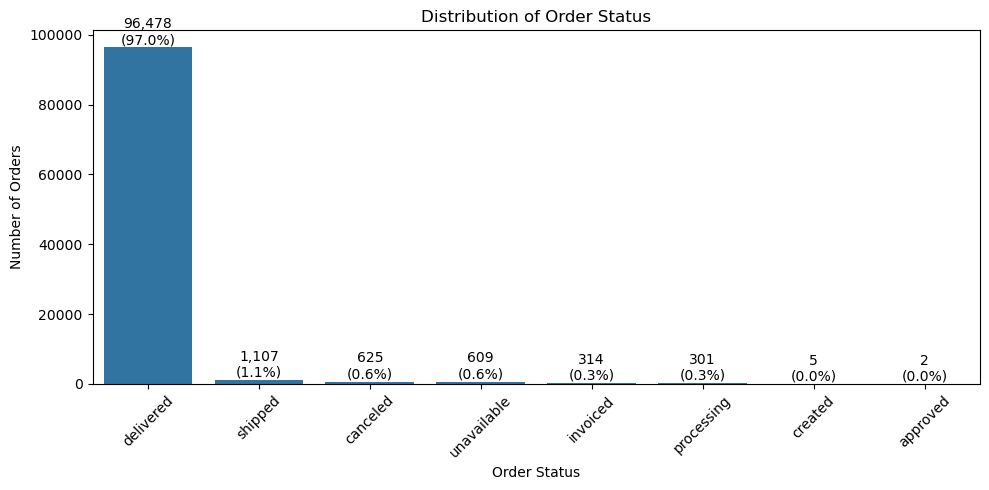

In [4]:
order_status_counts = orders_cleaned["order_status"].value_counts()
total_orders = order_status_counts.sum()

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=order_status_counts.index,
    y=order_status_counts.values
    
)

plt.title("Distribution of Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

# Add count and percentage labels
for bar in ax.patches:
    count = bar.get_height()
    percentage = (count / total_orders) * 100

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        count,
        f"{int(count):,}\n({percentage:.1f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

#### Key Insights

- The 97% of orders have a `delivered` status, indicating that most orders in the dataset were successfully completed.
- `shipped` and `canceled` orders represent a much smaller share of the total order volume.

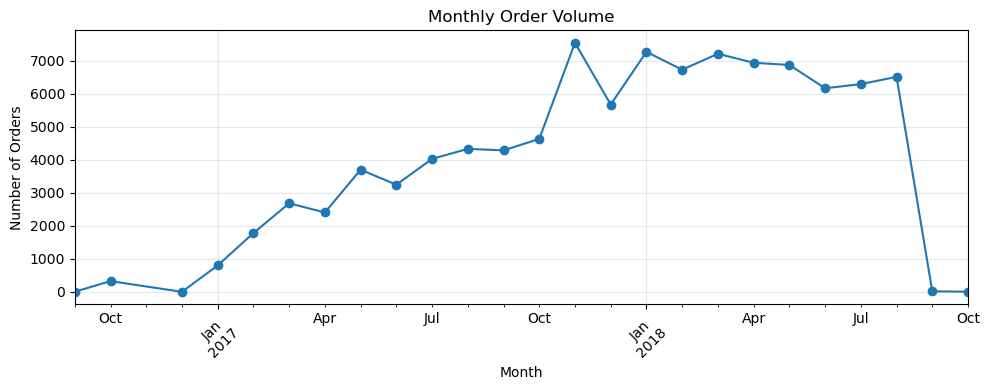

In [44]:
monthly_orders = (
    orders_cleaned.groupby(orders_cleaned['order_purchase_timestamp'].dt.to_period("M")).size()
    )
monthly_orders

plt.figure(figsize=(10, 4))

monthly_orders.plot(kind="line", marker="o")

plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### Key Insights

- Monthly order volume shows a clear growth trend during the earlier part of the observed period.
- Order volume reached its highest level toward the later part of the main growth period.
- A noticeable decline appears near the end of the observation period . the decline may be influenced by incomplete observations in the final period.

In [6]:
valid_orders = orders_cleaned[orders_cleaned['purchase_to_customer_hours'] >= 0]
to_days = (valid_orders['purchase_to_customer_hours'] / 24)

to_days.agg(['min', 'mean', 'median','max'])

min         0.533414
mean       12.558702
median     10.217755
max       209.628611
Name: purchase_to_customer_hours, dtype: float64

In [7]:
to_days.describe(percentiles=[.25, .5, .75, .9, .95])

count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
90%         23.097604
95%         29.276016
max        209.628611
Name: purchase_to_customer_hours, dtype: float64

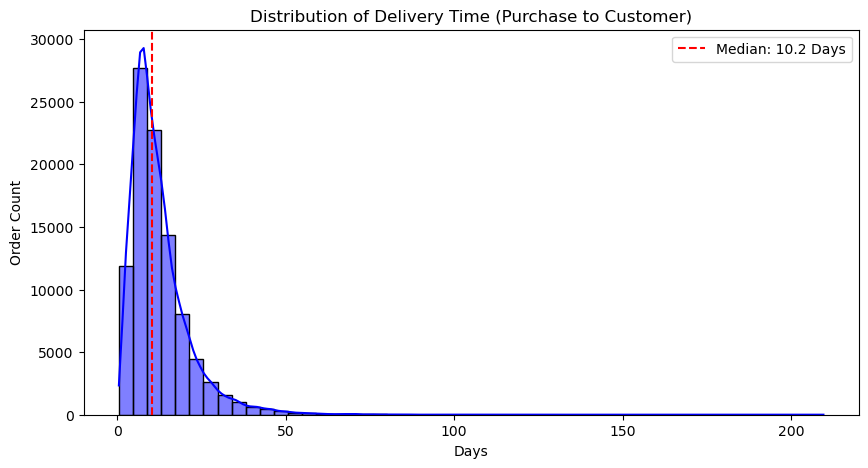

In [8]:
plt.figure(figsize=(10, 5))
sns.histplot(to_days, kde=True, bins=50, color='blue')
plt.title('Distribution of Delivery Time (Purchase to Customer)')
plt.xlabel('Days')
plt.ylabel('Order Count')
plt.axvline(to_days.median(), color='red', linestyle='--', label=f'Median: {to_days.median():.1f} Days')
plt.legend()
plt.show()

 #### Key Observation
Delivery time distribution is right-skewed, with most orders concentrated at shorter delivery times and a smaller number of orders taking considerably longer.

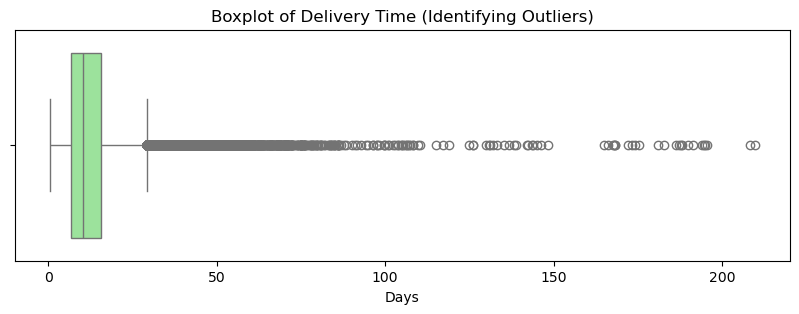

In [9]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=to_days, color='lightgreen')
plt.title('Boxplot of Delivery Time (Identifying Outliers)')
plt.xlabel('Days')
plt.show()

#### Key Observation

- The boxplot confirms the presence of a right-skewed distribution and several high-duration outliers.
- These outliers represent unusually long delivery times and were retained because they may reflect real business cases.

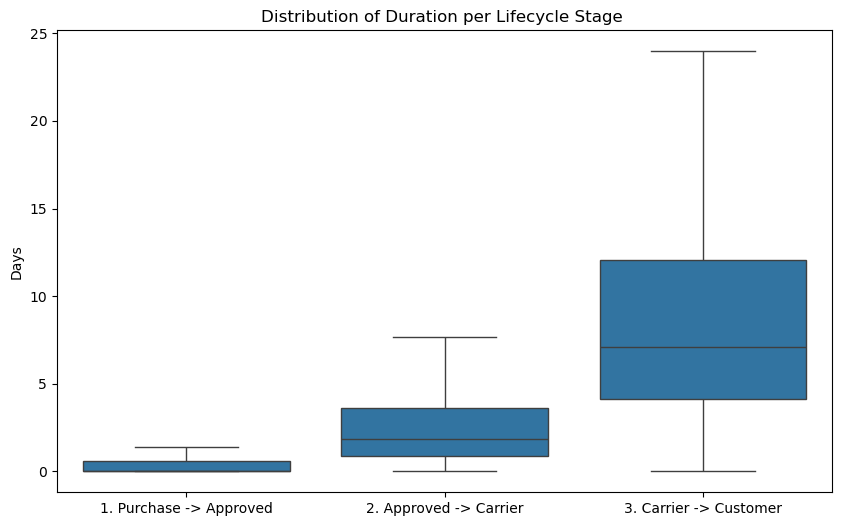

In [10]:
valid_lifecycle = orders_cleaned[
    (orders_cleaned['purchase_to_approved_hours'] >= 0) &
    (orders_cleaned['approval_to_carrier_hours'] >= 0) &
    (orders_cleaned['carrier_to_customer_hours'] >= 0)
]

lifecycle_long = pd.DataFrame({
    '1. Purchase -> Approved': valid_lifecycle['purchase_to_approved_hours'] / 24,
    '2. Approved -> Carrier': valid_lifecycle['approval_to_carrier_hours'] / 24,
    '3. Carrier -> Customer': valid_lifecycle['carrier_to_customer_hours'] / 24
}).melt(var_name='Stage', value_name='Days')

plt.figure(figsize=(10, 6))
sns.boxplot(data=lifecycle_long, x='Stage', y='Days', showfliers=False)
plt.title('Distribution of Duration per Lifecycle Stage ')
plt.ylabel('Days')
plt.xlabel('')
plt.show()

#### Key Observation
Carrier → Customer has the highest median duration and therefore represents the longest stage of the observed order lifecycle.

In [11]:
## 4. Delivery Performance

delivered_valid = orders_cleaned[
    (orders_cleaned['order_delivered_customer_date'].notna())
].copy()

delivered_valid['is_on_time'] = (
    delivered_valid['order_delivered_customer_date'] <= delivered_valid['order_estimated_delivery_date']
)

In [12]:
on_time_rate = delivered_valid['is_on_time'].mean() * 100
print(f"on time rate :  {on_time_rate:.2f}%")
print(f"total orders : {len(delivered_valid)}")

on time rate :  91.89%
total orders : 96476


#### Key Insights

- Approximately 91.89% of delivered orders were delivered on or before the estimated delivery date.
- This indicates that the majority of orders were delivered within the promised timeframe.
- However, approximately 8.11% of delivered orders were delivered after the estimated date, indicating that late delivery remains a relevant operational issue.
- The overall on-time delivery rate provides a high-level view of delivery performance, but it does not explain the causes of late deliveries.

## Order Items Analysis

### How are item prices distributed?

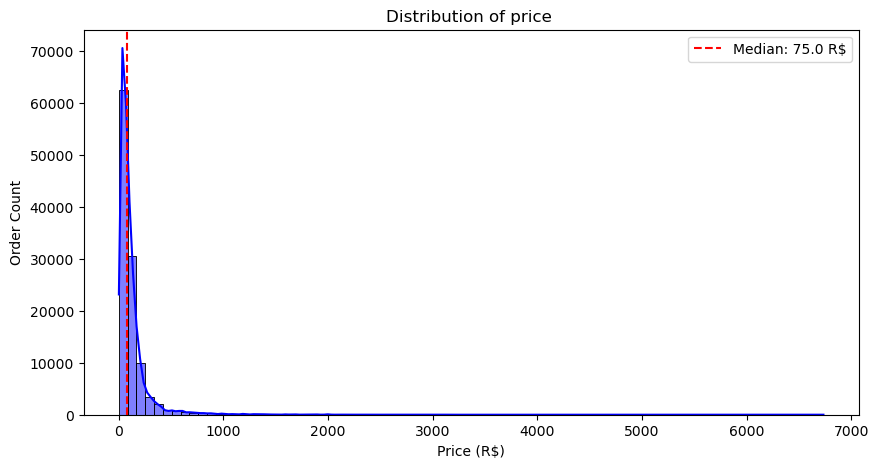

count    112650.000000
mean        120.653739
std         183.633928
min           0.850000
25%          39.900000
50%          74.990000
75%         134.900000
90%         229.800000
95%         349.900000
max        6735.000000
Name: price, dtype: float64

In [39]:
peice_dis = order_items_cleaned['price']
plt.figure(figsize=(10, 5))
sns.histplot(peice_dis, kde=True, bins=80, color='blue')
plt.title('Distribution of price ')
plt.xlabel('Price (R$)')
plt.ylabel('Order Count')
plt.axvline(peice_dis.median(), color='red', linestyle='--', label=f'Median: {peice_dis.median():.1f} R$')
plt.legend()
plt.show()

order_items_cleaned['price'].describe(
    percentiles=[.25, .5, .75, .9, .95]
)

#### Key Observation

- The mean item price is substantially higher than the median, and the distribution is positively skewed.
- Most items are concentrated at relatively lower price levels, while a smaller number of high-priced items create a long right tail.

### How are freight costs distributed?

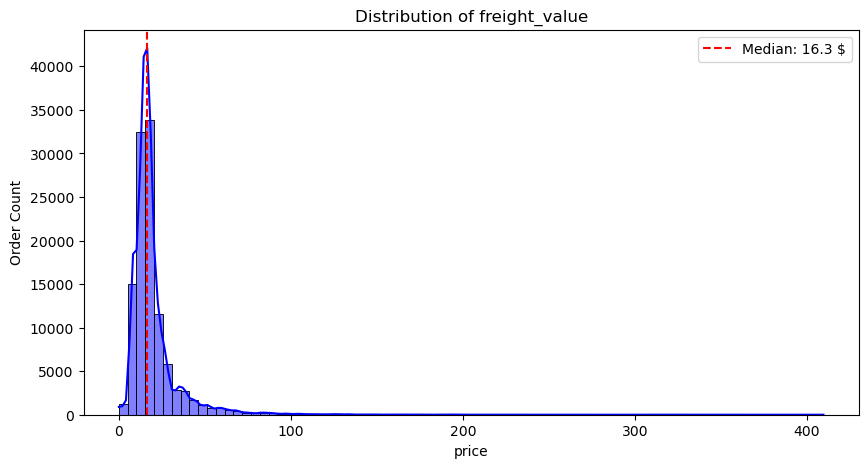

count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
90%          34.041000
95%          45.120000
max         409.680000
Name: freight_value, dtype: float64

In [ ]:
freight_value_dis = order_items_cleaned['freight_value']
plt.figure(figsize=(10, 5))
sns.histplot(freight_value_dis, kde=True, bins=80, color='blue')
plt.title('Distribution of freight_value')
plt.xlabel('Freight Value (R$)')
plt.ylabel('Order Count')
plt.axvline(freight_value_dis.median(), color='red', linestyle='--', label=f'Median: {freight_value_dis.median():.1f} $')
plt.legend()
plt.show()

order_items_cleaned['freight_value'].describe(
    percentiles=[.25, .5, .75, .9, .95]
)

In [40]:
zero_freight = (order_items_cleaned['freight_value'] == 0).sum()

zero_freight_pct = (
    zero_freight / len(order_items_cleaned) * 100
)

print(f"Zero freight items: {zero_freight:,}")
print(f"Percentage: {zero_freight_pct:.2f}%")

Zero freight items: 383
Percentage: 0.34%


### key observation 

- 383 of the order items have 0 shipping costs, which is likely due to proximity or discounts.

### How many items do customers typically purchase per order?

In [37]:
items_per_order = (
    order_items_cleaned
    .groupby('order_id')['order_item_id']
    .max()
)

items_per_order.describe(percentiles=[.25, .5, .75, .9, .95])

count    98666.000000
mean         1.141731
std          0.538452
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
90%          1.000000
95%          2.000000
max         21.000000
Name: order_item_id, dtype: float64

### Key Observations

- Most orders contain a single item, as the median number of items per order is 1.
- At least 90% of orders contain only one item.

### Is item price associated with freight value?

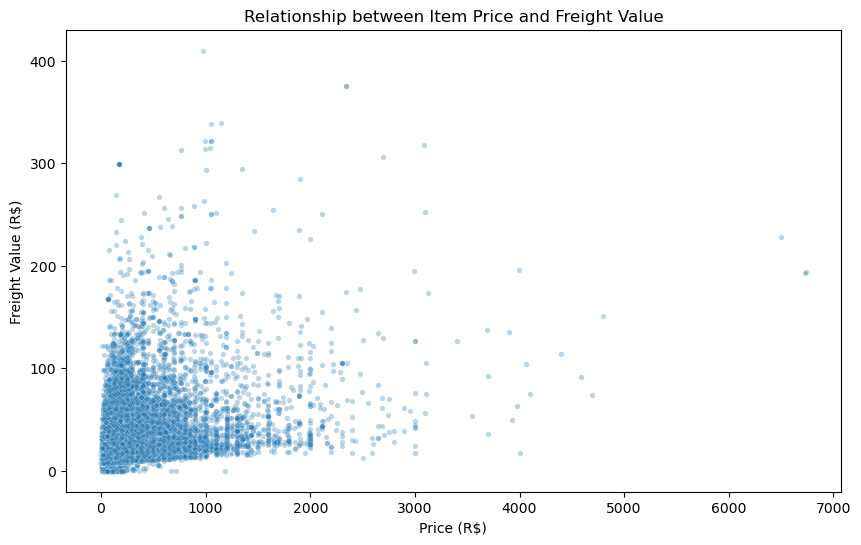

np.float64(0.434190324041091)

In [22]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=order_items_cleaned, x='price', y='freight_value', alpha=0.3, s=15)
plt.title('Relationship between Item Price and Freight Value')
plt.xlabel('Price (R$)')
plt.ylabel('Freight Value (R$)')
plt.show()

correlation_spearman = order_items_cleaned['price'].corr(order_items_cleaned['freight_value'], method='spearman')
correlation_spearman

### Key Observations

- A moderate positive monotonic relationship exists between item price and freight value (Spearman ρ = 0.434).
- Higher-priced items tend to be associated with higher freight values, but the relationship is not strong enough to explain freight costs by price alone.
- The wide dispersion of freight values at similar price levels suggests that other factors may also be associated with shipping costs.

### How significant is freight cost relative to item price?

In [42]:
order_items_cleaned['freight_ratio'] = (
    order_items_cleaned['freight_value']
    / order_items_cleaned['price']
)
order_items_cleaned['freight_ratio'].describe(
    percentiles=[.5, .75, .9, .95]
)

count    112650.000000
mean          0.320864
std           0.349894
min           0.000000
50%           0.231356
75%           0.393036
90%           0.642857
95%           0.874702
max          26.235294
Name: freight_ratio, dtype: float64